## Match Baseline Setup

In [17]:
import os
os.environ["PYTHONWARNINGS"] = "ignore"
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, FunctionTransformer, OneHotEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold, GridSearchCV, cross_validate, cross_val_predict
from sklearn.metrics import (roc_auc_score, f1_score, precision_score, recall_score, accuracy_score,
                             average_precision_score, brier_score_loss, confusion_matrix, ConfusionMatrixDisplay)
from sklearn.calibration import calibration_curve
import joblib

DATA_PATH = "../../../data/merges/CS_PSEO_IPEDS_BLS_ETPL_merged.csv"
OUTPUT_DIR = "../../../models/lr_tfidf_tuned"
RANDOM_STATE = 42
INCLUDE_DEMOGRAPHICS = False    # same decision as the baseline

# Threshold rule (Step 8). "max_f1" = best balance of precision and recall.
# "precision_floor" = highest recall while keeping precision >= PRECISION_FLOOR (stricter about false positives).
THRESHOLD_RULE = "max_f1"
PRECISION_FLOOR = 0.96

df = pd.read_csv(DATA_PATH, low_memory=False)
print("Shape:", df.shape)

Shape: (26678, 245)


In [18]:
drop_cols = ["CREDLEV", "CREDDESC", "CURROPER",
             "CIPCODE_str", "cip4", "CIP_family", "cip_code", "cip_2digit", "ST_FIPS",
             "TUITIONFEE_OUT_was_missing", "PCTFLOAN_was_missing",
             "DISTANCEONLY", "LOCALE_-3.0", "PREDDEG_4.0", "HIGHDEG_0.0", "has_pseo_match", "cip_match_level",
             "offers_undergrad", "enrolls_ft_undergrad", "offers_distance_courses",
             "xw_occ_mean_wage", "y1_earnings_natl_cip_family", "y5_earnings_natl_cip_family", "weeks_to_complete",
             "ay_tuition_indistrict", "ay_fee_indistrict", "ay_credithr_indistrict", "ay_pub_tuitfee_indistrict",
             "etpl_state_completion_median", "etpl_state_employment_q2_median", "etpl_state_earnings_median",
             "etpl_state_contact_hours_median", "etpl_state_tuition_median",
             "etpl_natl_completion_median", "etpl_natl_employment_q2_median", "etpl_natl_earnings_median",
             "etpl_natl_contact_hours_median", "etpl_natl_tuition_median",
             "local_earnings_index_state", "local_earnings_index_region",
             "prog_tuition_fees", "total_prog_cost",
             "ADM_RATE", "program_slot", "length_unit_code", "xw_has_hot_technology"]
df = df.drop(columns=drop_cols, errors="ignore").copy()
print("Shape after drop:", df.shape)

Shape after drop: (26678, 199)


In [19]:
TARGET = "vae_positive_local"
labeled = df.dropna(subset=[TARGET]).copy()
y = labeled[TARGET].astype(int)
groups = labeled["UNITID"]
print("Labeled programs:", len(labeled), "| schools:", groups.nunique(), f"| pass rate: {y.mean():.1%}")

Labeled programs: 7024 | schools: 2079 | pass rate: 78.3%


In [20]:
def build_text(frame):
    text = (frame["CIPDESC"].fillna("") + " | " + frame["xw_top_occupations"].fillna(""))
    return (text.str.lower()
                .str.replace(r"[^a-z\s]", " ", regex=True)
                .str.replace(r"\s+", " ", regex=True)
                .str.strip())

df["program_text"] = build_text(df)
labeled["program_text"] = df.loc[labeled.index, "program_text"]
print("Unique text values:", df["program_text"].nunique())

Unique text values: 360


## Numeric features (with the tuning changes)

Same exclusions as the baseline (leakage, IDs, fairness-only, duplicate formats, `etpl_prog_*`, demographics), then:

**Change 1: remove overlapping features.** Each pair below carries nearly the same information. Keeping both makes
logistic regression split the effect between them, often with opposite signs, which made the baseline's
coefficients hard to explain.

| Removed | Kept instead | Overlap |
|---|---|---|
| `TUITIONFEE_IN`, `TUITIONFEE_OUT` | `ay_pub_tuitfee_instate`, `COSTT4_A` | Scorecard and IPEDS publish the same tuition |
| `ay_tuition_instate`, `ay_tuition_outstate`, `ay_fee_instate`, `ay_fee_outstate`, `ay_pub_tuitfee_outstate`, `ay_credithr_outstate` | `ay_pub_tuitfee_instate`, `ay_credithr_instate` | Tuition + fees = published tuition/fees; in-state vs out-of-state nearly identical for certificates |
| `is_short_term_cert_provider` | `offers_cert_under_12wks` | Same flag (they offset each other in the baseline) |
| `IPEDSCOUNT2` | `IPEDSCOUNT1` | Completions in consecutive years |
| `y5_earnings_natl_cip_series`, `y5_earnings_natl_benchmark` | the `y1_` versions | 1-yr and 5-yr field benchmarks move together; the target is 1-yr |
| `CONTROL_Public` | (reference category) | Exactly determined by the other two CONTROL columns |
| `py_offcampus_family_other` | `py_offcampus_other` | Near-copy |
| `TUITIONFEE_IN_was_missing`, `COSTT4_A_was_missing`, `ay_books_supplies_missing` | `ay_pub_tuitfee_instate_missing` | r ≥ 0.97: all mean "school reports academic-year pricing" |
| `RET_FTL4_was_missing` | `C150_L4_was_missing` | r = 0.94 |
| `prog_supplies_missing` | `py_books_supplies_missing` | r = 0.93 |
| `degree_granting`, `AVGFACSAL_was_missing` | `HIGHDEG_*` one-hots | r ≥ 0.97 |
| `offers_grad` | `HIGHDEG_4.0` | r = 0.97 |
| `etpl_natl_n_with_outcomes` | `etpl_natl_n_programs` | r = 0.97 |
| `xw_skill_record_count` | `xw_unique_software_skills` | r = 0.92 |

**Change 2:** `CIPCODE` (a number) is dropped; `CIP_series` (2-digit family) and `calendar_system` become one-hot categories.

No automatic missing flags are added on top (an earlier version did; it created dozens more near-duplicate columns with opposite signs and scored lower).

**Change 3:** skewed, non-negative continuous columns get `log1p`.

In [21]:
LEAKAGE = ["EARN_MDN_1YR", "EARN_MDN_5YR", "EARN_MDN_HI_1YR", "EARN_COUNT_WNE_1YR", "EARN_COUNT_WNE_5YR",
           "y1_earnings_program", "y5_earnings_program", "y1_earnings_program_status", "y5_earnings_program_status",
           "earnings_1yr", "earnings_1yr_local_adj", "value_added_earnings_local", "earnings_vs_local_field",
           "vae_positive_local", "passes_vae_local"]
ID_TEXT = ["UNITID", "OPEID6", "INSTNM", "city", "ZIP", "LATITUDE", "LONGITUDE",
           "CIPDESC", "xw_top_occupations", "program_text"]
FAIRNESS_ONLY = ["HBCU", "TRIBAL", "ANNHI", "NANTI"]
DUPLICATE_FORMAT = ["control", "sector", "iclevel", "bea_region", "state", "highest_offering",
                    "etpl_bench_level", "local_index_level", "length_unit", "price_reporting",
                    "y1_earnings_natl_benchmark_level", "y5_earnings_natl_benchmark_level"]
ETPL_PROGRAM = [c for c in df.columns if c.startswith("etpl_prog_")]
DEMOGRAPHICS = [c for c in df.columns if c.startswith("UGDS_") and c not in ("UGDS_was_missing", "UGDS")]

exclude = set(LEAKAGE + ID_TEXT + FAIRNESS_ONLY + DUPLICATE_FORMAT + ETPL_PROGRAM)
if not INCLUDE_DEMOGRAPHICS:
    exclude |= set(DEMOGRAPHICS)

numeric = df[[c for c in df.columns if c not in exclude]].copy()
for c in numeric.columns:
    if numeric[c].dtype == object:
        numeric[c] = numeric[c].map({True: 1, False: 0, "True": 1, "False": 0})
numeric = numeric.apply(pd.to_numeric, errors="coerce")
numeric = numeric.loc[:, numeric.notna().any()]
BASELINE_FEATURES = numeric.columns.tolist()          # the baseline's 144, kept for the comparison in Step 6
df[BASELINE_FEATURES] = numeric
labeled[BASELINE_FEATURES] = numeric.loc[labeled.index]

REDUNDANT = ["TUITIONFEE_IN", "TUITIONFEE_OUT", "ay_tuition_instate", "ay_tuition_outstate", "ay_fee_instate",
             "ay_fee_outstate", "ay_pub_tuitfee_outstate", "ay_credithr_outstate", "is_short_term_cert_provider",
             "IPEDSCOUNT2", "y5_earnings_natl_cip_series", "y5_earnings_natl_benchmark", "CONTROL_Public",
             "py_offcampus_family_other",
             # duplicate missing-value flags and other near-copies (|r| >= 0.92)
             "TUITIONFEE_IN_was_missing", "COSTT4_A_was_missing", "ay_books_supplies_missing", "RET_FTL4_was_missing",
             "prog_supplies_missing", "degree_granting", "AVGFACSAL_was_missing", "offers_grad",
             "etpl_natl_n_with_outcomes", "xw_skill_record_count"]
CATEGORICAL = ["CIP_series", "calendar_system"]
FEATURES = [c for c in BASELINE_FEATURES if c not in REDUNDANT + CATEGORICAL + ["CIPCODE"]]

lab_num = labeled[FEATURES]
is_binary = lab_num.apply(lambda s: s.dropna().isin([0, 1]).all())
LOG_FEATURES = [c for c in FEATURES if not is_binary[c] and lab_num[c].min() >= 0 and abs(lab_num[c].skew()) > 1]
PLAIN_FEATURES = [c for c in FEATURES if c not in LOG_FEATURES]

print("Baseline numeric features:", len(BASELINE_FEATURES))
print(f"Removed as overlapping: {len(REDUNDANT)}")
print(f"Tuned: {len(FEATURES)} numeric ({len(LOG_FEATURES)} log-transformed) + {CATEGORICAL} one-hot")

Baseline numeric features: 144
Removed as overlapping: 24
Tuned: 117 numeric (32 log-transformed) + ['CIP_series', 'calendar_system'] one-hot


## Tuned pipeline

| Piece | Setting |
|---|---|
| `TfidfVectorizer` | words + 2-word phrases, English stop words, `sublinear_tf`; `max_features` and `min_df` tuned in Step 7 |
| Log block | `log1p` → median fill → scale |
| Plain numeric block | median fill → scale |
| `OneHotEncoder` | `CIP_series`, `calendar_system`; categories with < 10 programs grouped together |
| `LogisticRegression` | L2, `C` tuned, **no class weighting** (see Step 9) |

`make_baseline_pipeline` rebuilds the original baseline exactly, for side-by-side comparisons.

In [22]:
def make_tuned_pipeline(C=0.3, max_features=500, min_df=5, class_weight=None,
                        log=True, indicators=False, cip_onehot=True, drop_redundant=True):
    feats = [c for c in BASELINE_FEATURES if not (drop_redundant and c in REDUNDANT)]
    if cip_onehot:
        feats = [c for c in feats if c not in CATEGORICAL + ["CIPCODE"]]
    log_cols = [c for c in feats if c in LOG_FEATURES] if log else []
    plain_cols = [c for c in feats if c not in log_cols]
    impute = lambda: SimpleImputer(strategy="median", add_indicator=indicators)

    parts = [("text", TfidfVectorizer(ngram_range=(1, 2), min_df=min_df, stop_words="english",
                                      sublinear_tf=True, max_features=max_features), "program_text")]
    if log_cols:
        parts.append(("log", make_pipeline(FunctionTransformer(np.log1p, feature_names_out="one-to-one"),
                                           impute(), StandardScaler()), log_cols))
    parts.append(("num", make_pipeline(impute(), StandardScaler()), plain_cols))
    if cip_onehot:
        parts.append(("cip", OneHotEncoder(handle_unknown="ignore", min_frequency=10), CATEGORICAL))
    clf = LogisticRegression(C=C, class_weight=class_weight, max_iter=5000, solver="lbfgs")
    return Pipeline([("prep", ColumnTransformer(parts, remainder="drop")), ("clf", clf)])


def make_baseline_pipeline(C=1.0):
    pre = ColumnTransformer([
        ("text", TfidfVectorizer(ngram_range=(1, 2), min_df=5, stop_words="english",
                                 sublinear_tf=True, max_features=2000), "program_text"),
        ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), BASELINE_FEATURES)])
    return Pipeline([("prep", pre), ("clf", LogisticRegression(C=C, class_weight="balanced", max_iter=5000))])


X = labeled[["program_text"] + BASELINE_FEATURES]
cv = GroupKFold(n_splits=5)
scoring = {"accuracy": "accuracy", "precision": "precision", "recall": "recall", "f1": "f1",
           "roc_auc": "roc_auc", "pr_auc": "average_precision", "brier": "neg_brier_score"}
print("Pipelines ready.")

Pipelines ready.


## What each change contributes (ablation)
Changes are added one at a time, all at threshold 0.5 and with balanced weighting, so only the feature changes differ.
`PR-AUC` (average precision) is added because it's more sensitive than ROC-AUC when classes are imbalanced.

In [23]:
def summarize(model, Xm=X):
    s = cross_validate(model, Xm, y, cv=cv, groups=groups, scoring=scoring, n_jobs=-1)
    out = {m: s["test_" + m].mean() for m in scoring}
    out["brier"] = -out["brier"]
    out["roc_auc_std"] = s["test_roc_auc"].std()
    return out

steps = {
    "Baseline (as submitted)":            make_baseline_pipeline(),
    "+ log1p":                            make_tuned_pipeline(C=1, max_features=2000, class_weight="balanced",
                                                              cip_onehot=False, drop_redundant=False),
    "+ one-hot CIP / calendar":           make_tuned_pipeline(C=1, max_features=2000, class_weight="balanced",
                                                              drop_redundant=False),
    "+ drop overlapping features":        make_tuned_pipeline(C=1, max_features=2000, class_weight="balanced"),
}
ablation = pd.DataFrame({k: summarize(v) for k, v in steps.items()}).T
ablation.round(4)

,accuracy,precision,recall,f1,roc_auc,pr_auc,brier,roc_auc_std
Baseline (as submitted),0.8861,0.9610,0.8908,0.9245,0.9473,0.9822,0.0851,0.0094
+ log1p,0.8833,0.9597,0.8885,0.9226,0.9481,0.9826,0.0852,0.0098
+ one-hot CIP / calendar,0.8851,0.9603,0.8903,0.9239,0.9484,0.9826,0.0847,0.0094
+ drop overlapping features,0.8862,0.9614,0.8907,0.9246,0.9494,0.9832,0.0834,0.0104


**Notes:**
- **Ranking ability improves a little:** ROC-AUC 0.947 → **0.949**, PR-AUC 0.982 → 0.983, Brier 0.085 → 0.083. Each step adds 0.0003–0.001, well inside the fold-to-fold spread (±0.01), so read this as "small but consistent", not a breakthrough.
- **F1 at the 0.5 cutoff doesn't move** (0.925 in every row). These changes improve ranking and explainability; the F1 gain comes later, from calibration and the threshold.
- **Dropping the 24 overlapping features is the biggest single step** (+0.001 ROC-AUC, lowest Brier) *and* the one that matters most for explainability (see the coefficients section): coefficients no longer cancel each other out.
- **Also tried and rejected** (from a separate exploratory run, so numbers differ slightly from the table above; not re-run here because L1/elastic net take several minutes):

| Variant | ROC-AUC | F1 @ 0.5 | Verdict |
|---|---|---|---|
| Automatic "was missing" flags for every blank column | 0.948 | 0.927 | Lower, and dozens of duplicate flags with opposite signs |
| L1 penalty (C = 0.1 / 0.3 / 1) | 0.946–0.947 | 0.922–0.923 | Slightly worse, 50× slower |
| Elastic net (l1_ratio 0.5) | 0.946–0.947 | 0.922–0.924 | Slightly worse |
| Spline features on all continuous columns | 0.942–0.945 | 0.922–0.925 | Overfits |
| Interactions with school type, Pell share, field earnings | 0.947 | 0.926 | No gain |
| TF-IDF unigrams only / up to 3-grams | 0.948 | 0.927 | Same |
| No text at all | 0.946 | 0.924 | Text still adds a little |

- **Takeaway:** a linear model tops out around 0.949 here. To rank programs better we need a non-linear model (the team's XGBoost reached 0.961). For logistic regression, the remaining gains are in calibration and the threshold.

## Hyperparameter search with nested cross-validation

- **Inner loop** (4 school-grouped folds inside each training split): picks `C`, TF-IDF `max_features` and `min_df` by ROC-AUC.
- **Outer loop** (the usual 5 folds): scores the chosen model on schools the search never saw.

This gives an honest estimate. The baseline tuned and scored on the same folds, which its notes flagged as slightly optimistic.

In [24]:
param_grid = {"clf__C": [0.03, 0.1, 0.3, 1, 3],
              "prep__text__max_features": [500, 2000],
              "prep__text__min_df": [2, 5, 20]}
inner_cv = GroupKFold(n_splits=4)

outer_rows, chosen = [], []
for k, (tr, te) in enumerate(cv.split(X, y, groups)):
    search = GridSearchCV(make_tuned_pipeline(), param_grid, cv=inner_cv, scoring="roc_auc", n_jobs=-1)
    search.fit(X.iloc[tr], y.iloc[tr], groups=groups.iloc[tr])
    p = search.predict_proba(X.iloc[te])[:, 1]
    outer_rows.append({"fold": k + 1, "ROC-AUC": roc_auc_score(y.iloc[te], p),
                       "PR-AUC": average_precision_score(y.iloc[te], p), "Brier": brier_score_loss(y.iloc[te], p)})
    chosen.append(search.best_params_)

nested = pd.DataFrame(outer_rows)
print(pd.concat([nested, pd.DataFrame(chosen)], axis=1).round(4).to_string(index=False))
print(f"\nNested ROC-AUC: {nested['ROC-AUC'].mean():.4f} ± {nested['ROC-AUC'].std():.4f}")

# Final hyperparameters: search once on all labeled data
search = GridSearchCV(make_tuned_pipeline(), param_grid, cv=cv, scoring="roc_auc", n_jobs=-1)
search.fit(X, y, groups=groups)
BEST = search.best_params_
print("Final hyperparameters:", BEST)

top = (pd.DataFrame(search.cv_results_)
         .sort_values("rank_test_score")[["params", "mean_test_score", "std_test_score"]].head(8))
top.round(4)

 fold  ROC-AUC  PR-AUC  Brier  clf__C  prep__text__max_features  prep__text__min_df
    1   0.9570  0.9868 0.0629     1.0                      2000                   2
    2   0.9448  0.9763 0.0728     1.0                      2000                   2
    3   0.9302  0.9755 0.0750     0.3                      2000                   2
    4   0.9599  0.9883 0.0536     0.3                      2000                  20
    5   0.9520  0.9847 0.0650     1.0                      2000                   2

Nested ROC-AUC: 0.9488 ± 0.0119
Final hyperparameters: {'clf__C': 3, 'prep__text__max_features': 2000, 'prep__text__min_df': 20}


,params,mean_test_score,std_test_score
29,"{'clf__C': 3, 'prep__text__max_features': 2000...",0.9493,0.0104
28,"{'clf__C': 3, 'prep__text__max_features': 2000...",0.9493,0.0103
24,"{'clf__C': 3, 'prep__text__max_features': 500,...",0.9493,0.0106
26,"{'clf__C': 3, 'prep__text__max_features': 500,...",0.9492,0.0106
25,"{'clf__C': 3, 'prep__text__max_features': 500,...",0.9492,0.0106
27,"{'clf__C': 3, 'prep__text__max_features': 2000...",0.9492,0.0101
21,"{'clf__C': 1, 'prep__text__max_features': 2000...",0.9492,0.0105
22,"{'clf__C': 1, 'prep__text__max_features': 2000...",0.9491,0.0105


**Notes:**
- **Nested ROC-AUC = 0.949 ± 0.012.** This is the honest number for the tuned model: the search never saw the schools it was scored on.
- **Nesting costs almost nothing:** the same-fold best score is 0.9493, vs. 0.9488 nested. The optimism the baseline notes worried about turns out to be negligible here.
- **Fold 3 is the weak spot (0.930 vs. 0.945–0.960 for the others).** The spread comes from *which schools* land in a fold, not from the hyperparameters: every fold picked similar settings.
- **The settings barely matter:** the top 8 grid entries are within 0.0002 of each other, and folds chose `C` = 0.3 or 1 while the final search chose 3. The model is insensitive to these choices, a sign of stability, not of a bad search.
- **Final settings: `C` = 3, 2,000 terms, `min_df` = 20.** A 500-term vocabulary scores the same (only 360 distinct texts exist).

## Choosing the decision threshold

The baseline used `class_weight="balanced"` with a 0.5 cutoff. That's a fixed, implicit choice of how much a false
positive costs relative to a false negative. Here we train **without** weighting (calibrated probabilities, Step 9)
and choose the cutoff explicitly.

To keep this honest, the threshold is chosen **inside each training split** (from inner out-of-fold predictions) and then applied to the held-out schools.

In [25]:
def pick_threshold(y_true, prob, rule=THRESHOLD_RULE, floor=PRECISION_FLOOR):
    grid = np.round(np.arange(0.20, 0.951, 0.01), 2)
    rows = []
    for t in grid:
        pred = (prob >= t).astype(int)
        rows.append((t, precision_score(y_true, pred, zero_division=0), recall_score(y_true, pred), f1_score(y_true, pred)))
    tab = pd.DataFrame(rows, columns=["threshold", "precision", "recall", "f1"])
    if rule == "precision_floor":
        ok = tab[tab["precision"] >= floor]
        return (ok.sort_values(["recall", "threshold"], ascending=[False, True]).iloc[0]["threshold"]
                if len(ok) else 0.95), tab
    return tab.loc[tab["f1"].idxmax(), "threshold"], tab

def make_best():
    return make_tuned_pipeline().set_params(**BEST)

# Out-of-fold probabilities (each program scored by a model that never saw its school)
oof_prob = cross_val_predict(make_best(), X, y, cv=cv, groups=groups, method="predict_proba", n_jobs=-1)[:, 1]

# Nested threshold evaluation for both rules
nested_thr = []
for rule in ["max_f1", "precision_floor"]:
    preds = np.zeros(len(y), dtype=int); ts = []
    for tr, te in cv.split(X, y, groups):
        inner_p = cross_val_predict(make_best(), X.iloc[tr], y.iloc[tr], cv=inner_cv,
                                    groups=groups.iloc[tr], method="predict_proba", n_jobs=-1)[:, 1]
        t, _ = pick_threshold(y.iloc[tr], inner_p, rule=rule)
        ts.append(t)
        preds[te] = (oof_prob[te] >= t).astype(int)
    nested_thr.append({"rule": rule, "thresholds chosen": ts,
                       "accuracy": accuracy_score(y, preds), "precision": precision_score(y, preds),
                       "recall": recall_score(y, preds), "f1": f1_score(y, preds),
                       "false positives": int(((preds == 1) & (y == 0)).sum()),
                       "false negatives": int(((preds == 0) & (y == 1)).sum())})
nested_thr = pd.DataFrame(nested_thr).set_index("rule")

# Final threshold for scoring all programs
THRESHOLD, thr_table = pick_threshold(y, oof_prob)
print(f"Rule: {THRESHOLD_RULE} -> threshold = {THRESHOLD:.2f}\n")
nested_thr.round(3)

Rule: max_f1 -> threshold = 0.47



,thresholds chosen,accuracy,precision,recall,f1,false positives,false negatives
rule,,,,,,,
max_f1,"[0.55, 0.44, 0.46, 0.4, 0.43]",0.910,0.929,0.959,0.943,406,227
precision_floor,"[0.76, 0.75, 0.77, 0.76, 0.79]",0.889,0.962,0.895,0.927,197,580


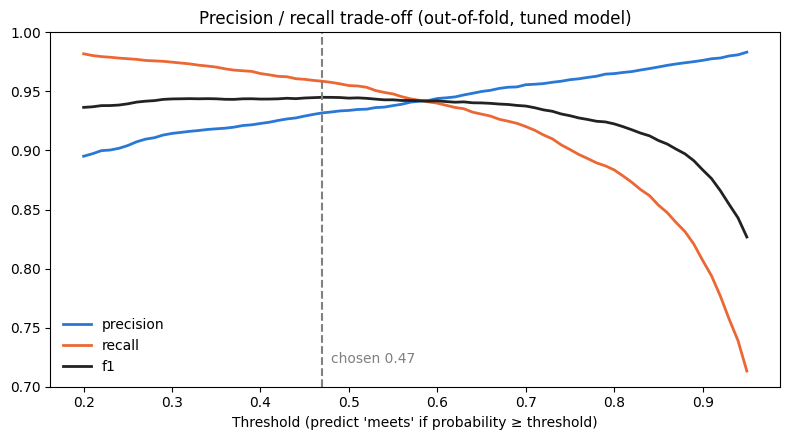

 threshold  precision  recall    f1
       0.3      0.914   0.975 0.944
       0.4      0.923   0.965 0.944
       0.5      0.934   0.955 0.944
       0.6      0.944   0.940 0.942
       0.7      0.956   0.920 0.938
       0.8      0.965   0.884 0.922
       0.9      0.976   0.807 0.884


In [26]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for col, c in [("precision", "#2a78d6"), ("recall", "#eb6834"), ("f1", "#222222")]:
    ax.plot(thr_table["threshold"], thr_table[col], label=col, color=c, lw=2)
ax.axvline(THRESHOLD, ls="--", color="grey"); ax.text(THRESHOLD + 0.01, 0.72, f"chosen {THRESHOLD:.2f}", color="grey")
ax.set_xlabel("Threshold (predict 'meets' if probability ≥ threshold)"); ax.set_ylim(0.7, 1.0)
ax.set_title("Precision / recall trade-off (out-of-fold, tuned model)"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

print(thr_table[thr_table["threshold"].isin([0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9])].round(3).to_string(index=False))

**Notes:**
- **The threshold is a policy choice, not a modeling one.** The ranking stays the same; the threshold only decides where to draw the "meets / doesn't" line. Both rows in the nested table are honest: the threshold was picked inside each training split and applied to unseen schools.
- **`max_f1` (default, thresholds 0.40–0.55; final 0.47):** F1 **0.925 → 0.943**, recall **0.891 → 0.959**, precision 0.961 → 0.929. Good programs overlooked drop from 601 to 227; false "meets" rise from 199 to 406.
- **`precision_floor` (precision ≥ 0.96, thresholds 0.75–0.79):** precision 0.962, recall 0.895, F1 0.927. It **matches or beats the baseline on both kinds of error** (197 vs. 199 false positives, 580 vs. 601 false negatives), so it's a safe improvement if the team wants to keep the baseline's caution.
- **The F1 curve is flat between 0.3 and 0.6 (0.942–0.944)**, so the exact `max_f1` threshold isn't fragile.
- **Recommendation:** put the **probability** into the Opportunity Score (that's what gets combined with completion, placement and demand) and use the threshold only for the yes/no flag on the dashboard. Which rule to use is the stakeholder's call; switching is one line in the setup cell.

## Calibration: can the probabilities be taken at face value?
The probability feeds the Opportunity Score (40% weight), so a predicted 0.8 should mean about 80% of such programs pass.
`class_weight="balanced"` makes the model act as if the classes were 50/50, which shifts every probability downward.

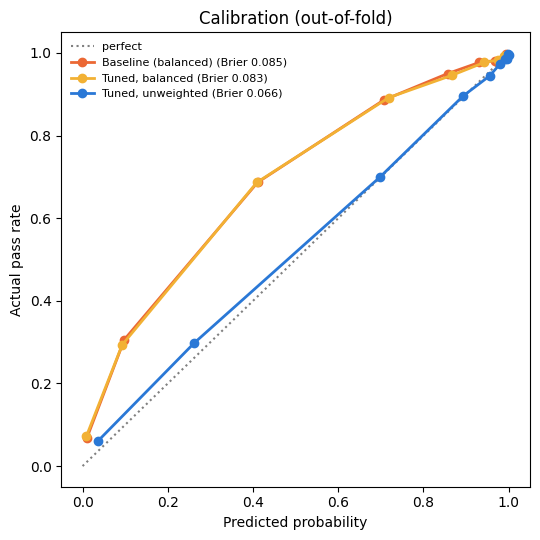

                   mean predicted  actual pass rate  ROC-AUC  \
Baseline                   0.6960            0.7835   0.9464   
Tuned, balanced            0.6999            0.7835   0.9485   
Tuned, unweighted          0.7809            0.7835   0.9483   

                   Brier (lower = better)  
Baseline                           0.0851  
Tuned, balanced                    0.0835  
Tuned, unweighted                  0.0663  


In [27]:
oof_bal = cross_val_predict(make_tuned_pipeline(class_weight="balanced").set_params(**BEST), X, y, cv=cv,
                            groups=groups, method="predict_proba", n_jobs=-1)[:, 1]
oof_base = cross_val_predict(make_baseline_pipeline(), X, y, cv=cv, groups=groups, method="predict_proba", n_jobs=-1)[:, 1]

fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.plot([0, 1], [0, 1], ls=":", color="grey", label="perfect")
for name, p, c in [("Baseline (balanced)", oof_base, "#eb6834"), ("Tuned, balanced", oof_bal, "#f2b134"),
                   ("Tuned, unweighted", oof_prob, "#2a78d6")]:
    fr, mp = calibration_curve(y, p, n_bins=10, strategy="quantile")
    ax.plot(mp, fr, marker="o", lw=2, color=c, label=f"{name} (Brier {brier_score_loss(y, p):.3f})")
ax.set_xlabel("Predicted probability"); ax.set_ylabel("Actual pass rate"); ax.legend(frameon=False, fontsize=8)
ax.set_title("Calibration (out-of-fold)"); plt.tight_layout(); plt.show()

print(pd.DataFrame({"mean predicted": [oof_base.mean(), oof_bal.mean(), oof_prob.mean()],
                    "actual pass rate": [y.mean()] * 3,
                    "ROC-AUC": [roc_auc_score(y, p) for p in (oof_base, oof_bal, oof_prob)],
                    "Brier (lower = better)": [brier_score_loss(y, p) for p in (oof_base, oof_bal, oof_prob)]},
                   index=["Baseline", "Tuned, balanced", "Tuned, unweighted"]).round(4))

**Notes:**
- **Weighting doesn't change ranking:** tuned ROC-AUC is 0.948 with or without `class_weight="balanced"`.
- **Without weighting, probabilities line up with reality:** the curve sits on the diagonal, the mean prediction (0.781) matches the actual pass rate (0.784), and the Brier score is **22% lower** (0.085 → 0.066). The balanced models sit below the diagonal: they say ~0.70 on average when the real rate is 0.78.
- **That's why the tuned model drops `class_weight="balanced"`:** imbalance is handled by the threshold, and the probability is safe to use directly in the Opportunity Score.

## Errors at the chosen threshold vs. the baseline (out-of-fold)

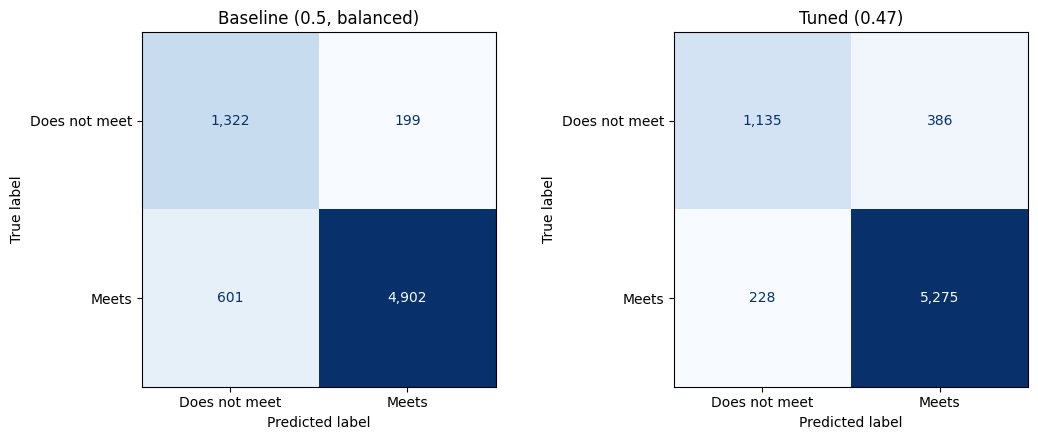

,accuracy,precision,recall,f1,roc_auc,pr_auc,brier,false positives,false negatives
Baseline,0.8861,0.9610,0.8908,0.9246,0.9464,0.9817,0.0851,199.0,601.0
Tuned,0.9126,0.9318,0.9586,0.9450,0.9483,0.9822,0.0663,386.0,228.0


In [28]:
oof_pred = (oof_prob >= THRESHOLD).astype(int)
base_pred = (oof_base >= 0.5).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (name, pred) in zip(axes, [("Baseline (0.5, balanced)", base_pred), (f"Tuned ({THRESHOLD:.2f})", oof_pred)]):
    ConfusionMatrixDisplay(confusion_matrix(y, pred), display_labels=["Does not meet", "Meets"]).plot(
        ax=ax, cmap="Blues", values_format=",", colorbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.show()

def metrics(pred, prob):
    return {"accuracy": accuracy_score(y, pred), "precision": precision_score(y, pred), "recall": recall_score(y, pred),
            "f1": f1_score(y, pred), "roc_auc": roc_auc_score(y, prob), "pr_auc": average_precision_score(y, prob),
            "brier": brier_score_loss(y, prob),
            "false positives": int(((pred == 1) & (y == 0)).sum()), "false negatives": int(((pred == 0) & (y == 1)).sum())}
compare = pd.DataFrame({"Baseline": metrics(base_pred, oof_base), "Tuned": metrics(oof_pred, oof_prob)}).T
compare.round(4)

## Coefficients after removing overlapping features
Same reading as the baseline: positive pushes toward "meets", negative toward "does not meet".
Numeric coefficients are per standard deviation (after `log1p` for the log block).

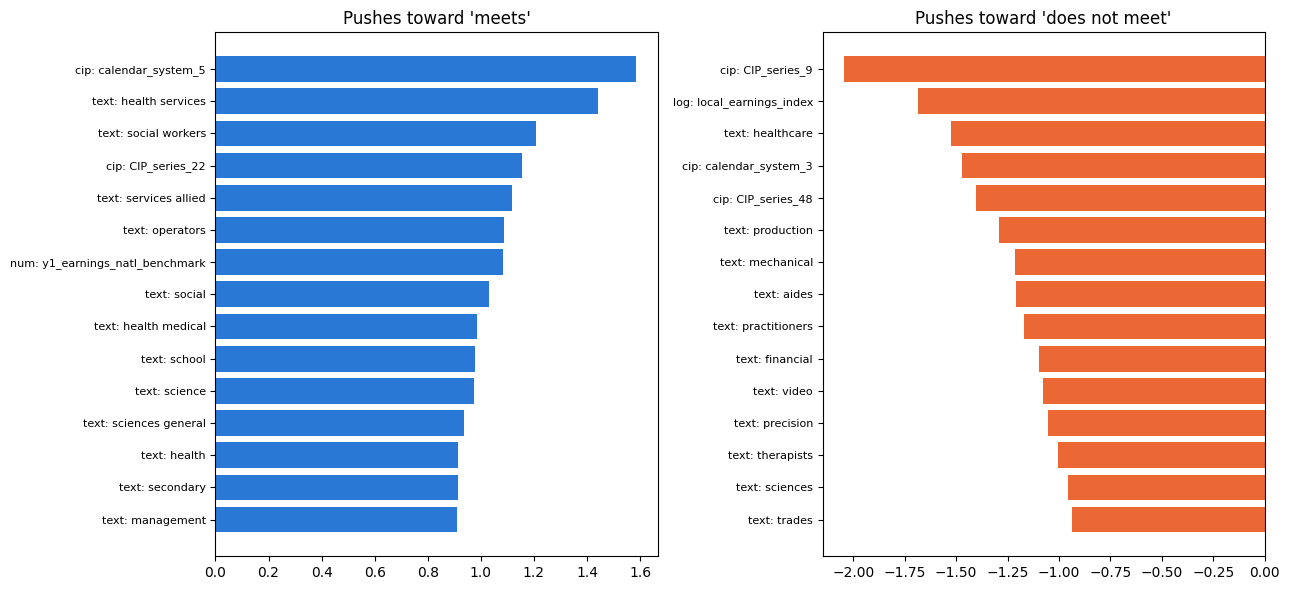

Cost / short-term features (previously had conflicting signs):
num: ay_pub_tuitfee_instate_missing   -0.471
log: program_cost                     -0.141
log: ay_pub_tuitfee_instate           -0.115
log: etpl_bench_tuition               -0.097
num: offers_cert_under_12wks           0.124
log: py_tuitfee                        0.178
num: COSTT4_A                          0.194


In [29]:
final_model = make_best().fit(X, y)
prep = final_model.named_steps["prep"]
names = [n.replace("__", ": ", 1) for n in prep.get_feature_names_out()]
coef_s = pd.Series(final_model.named_steps["clf"].coef_[0], index=names)

top_pos = coef_s.sort_values(ascending=False).head(15)
top_neg = coef_s.sort_values().head(15)
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
axes[0].barh(top_pos.index[::-1], top_pos.values[::-1], color="#2a78d6"); axes[0].set_title("Pushes toward 'meets'")
axes[1].barh(top_neg.index[::-1], top_neg.values[::-1], color="#eb6834"); axes[1].set_title("Pushes toward 'does not meet'")
for ax in axes:
    ax.tick_params(axis="y", labelsize=8); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

check = [n for n in coef_s.index if any(k in n for k in ["tuit", "TUITION", "COSTT4", "short_term", "cert_under_12wks", "program_cost"])]
print("Cost / short-term features (previously had conflicting signs):")
print(coef_s[check].sort_values().round(3).to_string())

**Notes:**
- **No more pairs cancelling out.** In the baseline, `offers_cert_under_12wks` (strongly +) and `is_short_term_cert_provider` (strongly −) were the same flag, and four tuition columns split between + and −. Now there's one short-term flag (mildly +) and one tuition column per source.
- **The remaining cost features measure different things, so mixed signs are now meaningful:**
  - Published tuition (`ay_pub_tuitfee_instate`), program cost and field-typical ETPL tuition are **negative**: costlier programs are slightly less likely to clear the earnings bar, other things equal.
  - `COSTT4_A` is **positive**, but it includes housing and living costs, so it partly tracks local cost of living.
  - `py_tuitfee` only exists for program-year (mostly clock-hour) schools, so it compares those schools with each other.
  - `ay_pub_tuitfee_instate_missing` (−0.46) is really "the school reports by program instead of by academic year", which is typical of short, clock-hour, often for-profit programs.
- **Label-construction effects remain** (`local_earnings_index`, Far West region): expected by design, as in the baseline.
- For explaining **individual** predictions in the dashboard, SHAP is still the better tool, but the global coefficients can now be read as a summary.

## Fairness check by school type (out-of-fold, chosen threshold)

In [30]:
rows = []
for name, pred, prob in [("Baseline", base_pred, oof_base), ("Tuned", oof_pred, oof_prob)]:
    for grp, idx in labeled.groupby("control").groups.items():
        pos = labeled.index.get_indexer(idx)
        yt = y.loc[idx]
        rows.append({"model": name, "control": grp, "programs": len(idx), "actual pass": yt.mean(),
                     "mean prob": prob[pos].mean(), "predicted pass": pred[pos].mean(),
                     "precision": precision_score(yt, pred[pos], zero_division=0), "recall": recall_score(yt, pred[pos]),
                     "F1": f1_score(yt, pred[pos]), "ROC-AUC": roc_auc_score(yt, prob[pos])})
fair = pd.DataFrame(rows).set_index(["control", "model"]).sort_index()
fair.round(3)

programs  actual pass  mean prob  predicted pass  \
control            model                                                        
Private for-profit Baseline      2737        0.566      0.447           0.463   
                   Tuned         2737        0.566      0.565           0.585   
Private non-profit Baseline       306        0.758      0.627           0.660   
                   Tuned          306        0.758      0.755           0.804   
Public             Baseline      3981        0.935      0.873           0.913   
                   Tuned         3981        0.935      0.931           0.958   

                             precision  recall     F1  ROC-AUC  
control            model                                        
Private for-profit Baseline      0.923   0.755  0.831    0.924  
                   Tuned         0.863   0.893  0.878    0.930  
Private non-profit Baseline      0.926   0.806  0.862    0.869  
                   Tuned         0.862   0.914  0.887    0.861  
Public             Baseline      0.976   0.952  0.964    0.917  
                   Tuned         0.965   0.989  0.977    0.912

**Notes:**
- **The baseline's main fairness gap mostly closes.** For-profit recall goes from **0.755 to 0.893** (about 1 in 4 good for-profit programs missed → about 1 in 9). Non-profit recall goes from 0.806 to 0.914.
- **Probabilities are calibrated within each school type:** mean predicted probability matches the actual pass rate (for-profit 0.565 vs. 0.566, non-profit 0.755 vs. 0.758, public 0.931 vs. 0.935). The baseline under-predicted every group by 6–13 points. This was the calibration-by-type check the baseline notes asked for.
- **Trade-off:** precision for private schools drops (for-profit 0.923 → 0.863, non-profit 0.926 → 0.862), and the yes/no flag now slightly *over*-predicts passing (for-profit 58.5% predicted vs. 56.6% actual, instead of 46% under the baseline). Under the `precision_floor` rule this reverses.
- **Within-group ROC-AUC (0.86–0.93) barely moves.** Non-profit dips from 0.869 to 0.861, which is noise with only 306 programs. Ranking programs *within* a school type is still the hard part, and a linear model can't improve it further.

## Score every program and save

In [31]:
os.makedirs(OUTPUT_DIR, exist_ok=True)

df["p_vae_lr_tuned"] = final_model.predict_proba(df[["program_text"] + BASELINE_FEATURES])[:, 1]
df["vae_flag_lr_tuned"] = (df["p_vae_lr_tuned"] >= THRESHOLD).astype(int)
df.loc[labeled.index, "p_vae_oof"] = oof_prob

out = df[["UNITID", "INSTNM", "state", "CIPCODE", "CIPDESC", "control",
          "vae_positive_local", "earnings_1yr", "p_vae_lr_tuned", "vae_flag_lr_tuned", "p_vae_oof"]]
out.to_csv(f"{OUTPUT_DIR}/lr_tfidf_tuned_predictions.csv", index=False)
joblib.dump({"model": final_model, "threshold": THRESHOLD, "threshold_rule": THRESHOLD_RULE, "params": BEST},
            f"{OUTPUT_DIR}/lr_tfidf_tuned_model.joblib")
compare.to_csv(f"{OUTPUT_DIR}/lr_tfidf_tuned_vs_baseline.csv")
ablation.to_csv(f"{OUTPUT_DIR}/lr_tfidf_tuned_ablation.csv")

print("Saved predictions:", out.shape, "| threshold:", THRESHOLD)
print("Unlabeled programs flagged 'meets':", f"{df.loc[~df.index.isin(labeled.index), 'vae_flag_lr_tuned'].mean():.1%}")

Saved predictions: (26678, 11) | threshold: 0.47
Unlabeled programs flagged 'meets': 91.2%


**Notes:**
- **91% of unlabeled programs are flagged "meets"** (vs. 78% of labeled ones). That's plausible, since unlabeled programs are mostly public (labeled data over-represents for-profit schools, 39% vs. 16%) and public programs pass 94% of the time. But these programs have no earnings data to check against, so treat their scores as extrapolations and prefer the probability over the flag.
- `p_vae_oof` is the honest score for labeled programs; `p_vae_lr_tuned` comes from the model fit on all labeled data.

## Summary

| | Baseline | Tuned |
|---|---|---|
| ROC-AUC (5-fold mean) | 0.947 | **0.949** (nested: 0.949) |
| F1 | 0.925 | **0.945** (`max_f1`, threshold 0.47) / 0.927 (`precision_floor`) |
| Precision / recall | 0.961 / 0.891 | 0.932 / 0.959 (`max_f1`) · 0.962 / 0.895 (`precision_floor`) |
| False positives / false negatives | 199 / 601 | 386 / 228 (`max_f1`) · 197 / 580 (`precision_floor`) |
| Brier (calibration, lower = better) | 0.085 | **0.066** |
| For-profit recall | 0.755 | **0.893** |
| Features | 144 numeric + text | 117 numeric + 2 one-hot categories + text |

- **Ranking ability:** small, consistent gain (0.947 → 0.949), mostly from removing 24 overlapping features. Logistic regression is at its ceiling here; L1, elastic net, splines and interactions didn't help. To rank better, use the non-linear models (XGBoost 0.961).
- **F1:** 0.925 → 0.945 at the `max_f1` threshold, chosen inside nested CV (honest estimate 0.943). With `"precision_floor"`, the model matches or beats the baseline on **both** false positives and false negatives.
- **Calibration:** dropping `class_weight="balanced"` makes probabilities match actual pass rates overall and within each school type, so the probability can go straight into the Opportunity Score.
- **Explainability:** no more coefficient pairs cancelling each other out; CIP family and calendar system treated as categories.
- **Fairness:** the for-profit recall gap from the baseline (0.755) mostly closes (0.893).
- **Open decision for the team / stakeholder:** which threshold rule to use for the yes/no flag. The probability itself doesn't depend on it.